# P5 프로젝트 · 서울 따릉이 대여소 이용 패턴

**K-means 군집화 | 3주 Lab**

> **핵심 질문:** 따릉이는 어느 시간에 **빌리고**, 어느 시간에 **반납**할까? 비슷한 대여소를 묶으면 운영에 도움이 될까?

P1에서는 자전거 이용량을 *예측*했습니다. P5에서는 정답 레이블 없이 대여소를 묶고, **그 결과에 의미가 있는지 판단**합니다.

| 단계 | 주요 활동 |
|---|---|
| **1단계** | 데이터의 의미와 대여·반납 패턴 이해 |
| **2단계** | K-means 군집화와 군집 수 결정 |
| **3단계** | 군집 해석, 대여·반납 불균형, 운영 방안 제안 |

코드를 처음부터 작성할 필요는 없습니다. **실행 → 관찰 → 설정 변경 → 해석**을 반복하세요. 코드를 읽는 데 필요한 설명은 각 단계에 짧게 제공합니다.

## 1단계 · 따릉이 데이터를 이해하자

### 1. 데이터 불러오기

**한 행 = 대여소 한 곳**이며, 모든 값은 **2025년**에 해당합니다.

| 열 이름 | 의미 |
|---|---|
| `annual_rentals` / `annual_returns` | 연간 대여건수 / 연간 반납건수 |
| `m01`~`m12` | 월별 **대여건수** 합계 |
| `r_wd_h08` | 2025년 모든 **평일 오전 8시대**의 대여건수 합계 |
| `b_we_h18` | 2025년 모든 **주말 오후 6시대**의 반납건수 합계 |

`r`은 대여(rental), `b`는 반납(return), `wd`는 평일(월~금), `we`는 주말(토~일), `h08`은 08:00~08:59입니다. **시간대 값은 일평균이 아니라 연간 해당 시간대의 총건수**입니다. 월별 열은 *대여*를 기준으로 집계했습니다.

먼저 **모의 데이터**로 실행합니다. 실제 서울시 자료가 준비되면 파일명만 변경하세요. 모의 데이터로 얻은 결과를 실제 서울시 분석 결과라고 해석하면 안 됩니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_FILE = "p5_demo_station_profiles_2025.csv"  # 실제 데이터: p5_station_profiles_2025.csv
bike = pd.read_csv(DATA_FILE, dtype={"station_id": str})
bike.head()

,station_id,station_name,annual_rentals,annual_returns,m01,m02,m03,m04,m05,m06,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,1000,모의 대여소 001,31019,30287,1030,309,2088,4776,4021,4459,...,651,531,542,474,228,186,95,84,65,59
1,1001,모의 대여소 002,64659,69822,2809,3503,4963,3183,12916,9600,...,1218,1728,1689,1557,1249,889,732,495,263,278
2,1002,모의 대여소 003,19521,20877,466,2182,982,2301,2184,1534,...,870,1235,1536,1845,1687,1314,912,608,381,222
3,1003,모의 대여소 004,17339,17682,1041,502,1781,2085,1369,2126,...,323,319,305,329,287,259,195,146,102,76
4,1004,모의 대여소 005,50069,49158,1316,2806,3310,4401,3346,7388,...,1110,975,1000,712,578,373,243,130,103,92


### 2. 전체 이용 규모 살펴보기

연간 대여건수와 반납건수는 반드시 같지 않습니다. 한 대여소에서 빌린 자전거를 다른 대여소에 반납할 수 있기 때문입니다.

In [2]:
bike[["annual_rentals", "annual_returns"]].describe().round(0)

,annual_rentals,annual_returns
count,260.0,260.0
mean,36365.0,36432.0
std,18194.0,18393.0
min,3737.0,3544.0
25%,19749.0,19997.0
50%,35312.0,36126.0
75%,51233.0,52244.0
max,64899.0,70428.0


### 3. 시간대별 대여·반납 패턴

**2025년 평일은 261일, 주말은 104일**입니다(공휴일은 요일만으로 구분). 평일과 주말의 총건수를 직접 비교하지 않고, 각각의 날짜 수로 나누어 **하루 평균 대여·반납건수**를 그려 봅니다.

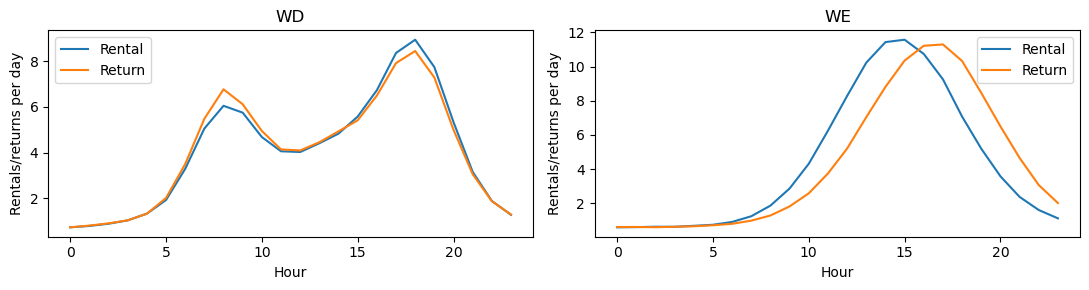

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, n in zip(axes, ["wd", "we"], [261, 104]):
    for kind, label in [("r", "Rental"), ("b", "Return")]:
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), bike[cols].mean().to_numpy() / n, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Rentals/returns per day")
    ax.legend()
plt.tight_layout()
plt.show()

**✍️ 기록 ①**

- 평일과 주말 중 대여가 집중되는 시간대는 언제인가요?
- 같은 시간에 **대여와 반납이 서로 다르게 나타나는 이유**를 추측해 보세요. 어디까지가 그래프에서 확인되는 사실이고, 어디부터가 가설인가요?
- 대여소별 이용량 차이가 큰데, 이를 그대로 K-means에 넣으면 무엇을 주로 묶게 될까요?

## 2단계 · K-means로 이용 유형 발견하기

### 4. 건수가 아니라 *시간대별 비중*으로 묶자

대여소 규모가 달라도 시간대별 패턴이 비슷한 곳을 찾으려면 **각 시간대 건수 ÷ 그 대여소의 연간 총건수**로 변환합니다.

- 대여 48개(평일·주말 × 24시간)의 비중 합은 **1**입니다.
- 반납 48개의 비중 합도 **1**입니다.
- 대여·반납 비중을 합쳐 **96개 특성**으로 K-means를 학습합니다.

이렇게 하면 이용 규모의 영향이 줄어듭니다. 다만 주말보다 평일의 날짜 수가 많으므로, **연간 비중은 평일이 상대적으로 크게 나타날 수 있다**는 점도 기억하세요.

In [4]:
rent_cols = [f"r_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]
return_cols = [f"b_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]

rent_share = bike[rent_cols].div(bike["annual_rentals"], axis=0)
return_share = bike[return_cols].div(bike["annual_returns"], axis=0)
X = pd.concat([rent_share, return_share], axis=1)
X.head()

,r_wd_h00,r_wd_h01,r_wd_h02,r_wd_h03,r_wd_h04,r_wd_h05,r_wd_h06,r_wd_h07,r_wd_h08,r_wd_h09,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,0.004675,0.003256,0.003740,0.004288,0.007834,0.022180,0.056127,0.094136,0.118444,0.117218,...,0.021494,0.017532,0.017895,0.015650,0.007528,0.006141,0.003137,0.002773,0.002146,0.001948
1,0.003511,0.004176,0.004810,0.004021,0.005738,0.009496,0.013007,0.020013,0.022889,0.023214,...,0.017444,0.024749,0.024190,0.022300,0.017888,0.012732,0.010484,0.007089,0.003767,0.003982
2,0.004662,0.004662,0.004610,0.004354,0.004457,0.004918,0.005686,0.005328,0.007274,0.008299,...,0.041673,0.059156,0.073574,0.088375,0.080807,0.062940,0.043684,0.029123,0.018250,0.010634
3,0.009747,0.010554,0.010324,0.012169,0.016379,0.022204,0.025549,0.027799,0.034662,0.032701,...,0.018267,0.018041,0.017249,0.018606,0.016231,0.014648,0.011028,0.008257,0.005769,0.004298
4,0.004514,0.003855,0.004753,0.005153,0.008828,0.022329,0.052867,0.097765,0.103996,0.096587,...,0.022580,0.019834,0.020343,0.014484,0.011758,0.007588,0.004943,0.002645,0.002095,0.001872


### 5. 군집 수는 몇 개가 적절할까?

`k`를 2~6까지 바꿔 보고 **실루엣 점수**를 비교합니다. 점수가 높을수록 군집 내부는 가깝고 다른 군집과는 멀리 떨어져 있다는 뜻입니다. 단, 점수만으로 군집의 의미가 보장되지는 않습니다.

In [5]:
results = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    score = silhouette_score(X, km.labels_, sample_size=500, random_state=42)
    results.append([k, score])

scores = pd.DataFrame(results, columns=["k", "silhouette"])
scores

c:\Users\gslee\miniforge3\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than 

,k,silhouette
0,2,0.496012
1,3,0.696487
2,4,0.826312
3,5,0.646786
4,6,0.467814


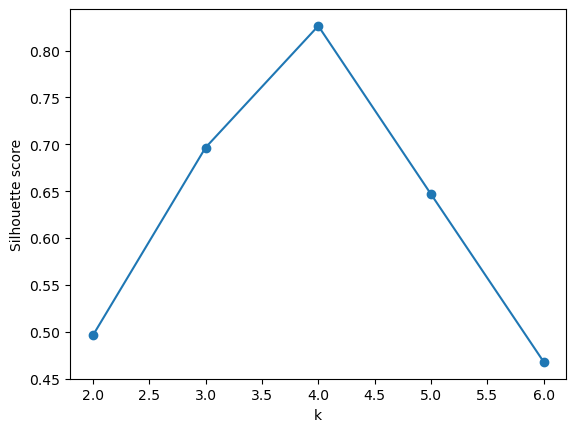

In [6]:
scores.plot(x="k", y="silhouette", marker="o", legend=False)
plt.ylabel("Silhouette score")
plt.show()

### 6. 선택한 군집의 평균 패턴

이제 `K`를 선택하세요. 아래 4개의 그래프는 각각 **평일 대여, 주말 대여, 평일 반납, 주말 반납**의 시간대별 비중입니다. 각 값은 해당 대여소의 연간 대여 또는 반납 총건수에 대한 백분율입니다.

c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\gslee\AppData\Local\Temp\ipykernel_41864\3553573554.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bike["cluster"] = model.fit_predict(X)


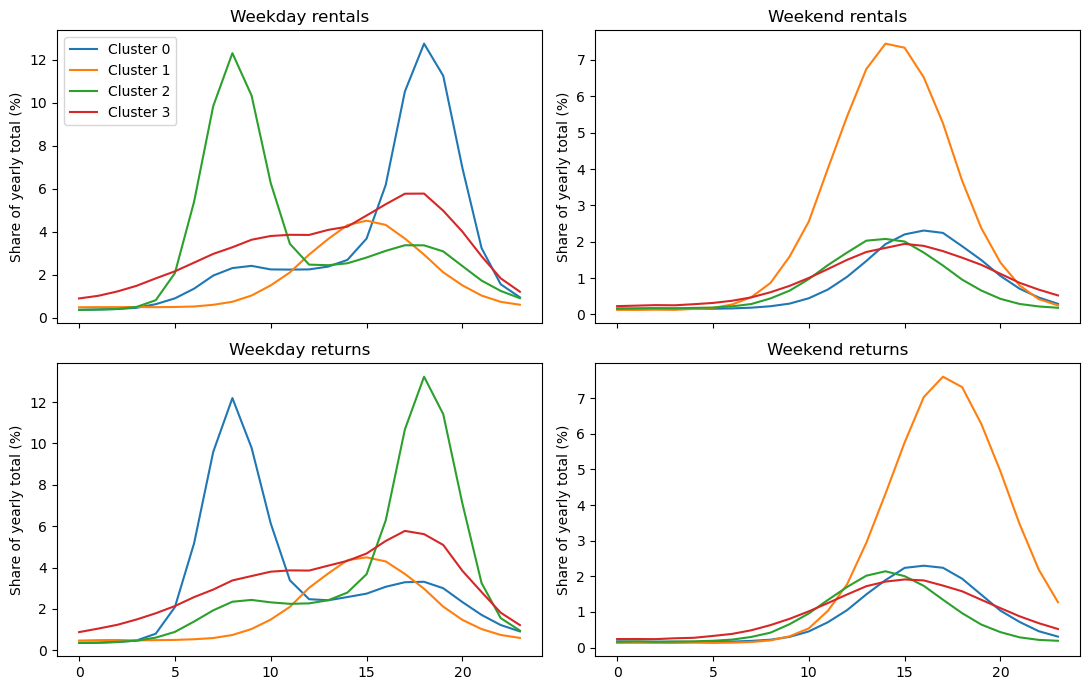

In [7]:
K = 4  # TODO: 실루엣 점수와 해석 가능성을 고려해 선택
model = KMeans(n_clusters=K, n_init=10, random_state=42)
bike["cluster"] = model.fit_predict(X)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, cols, title in zip(axes.flat,
                           [rent_cols[:24], rent_cols[24:], return_cols[:24], return_cols[24:]],
                           ["Weekday rentals", "Weekend rentals", "Weekday returns", "Weekend returns"]):
    for group, part in X.groupby(bike["cluster"]):
        ax.plot(range(24), part[cols].mean().to_numpy() * 100, label=f"Cluster {group}")
    ax.set(title=title, ylabel="Share of yearly total (%)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**✍️ 기록 ②**

- 선택한 `K`의 근거를 적으세요. 군집 수와 실루엣 점수는 어떻게 달라졌나요?
- 어떤 군집은 출근 시간대에 **대여**가 많고, 다른 군집은 **반납**이 많나요?
- 각 군집의 특성에 이름을 붙여 보세요. 단, 이름은 실제 이용 목적을 확인한 결과가 아니라 **해석 가설**입니다.

**AI 활용:** AI에게 군집 이름을 제안받은 뒤, 그래프만으로 뒷받침되지 않는 표현이 있는지 검토하세요.

## 3단계 · 발견한 군집이 운영에 도움이 될까?

### 7. 군집의 크기와 대여·반납 규모

군집화에는 비중을 사용했지만, 운영 문제를 생각하려면 실제 **대여·반납건수**도 봐야 합니다. 군집별 대여소 수와 연간 이용량의 중앙값을 비교해 봅시다.

In [8]:
bike.groupby("cluster").agg(
    stations=("station_id", "size"),
    rentals=("annual_rentals", "median"),
    returns=("annual_returns", "median")
).round(0)

,stations,rentals,returns
cluster,,,
0,65,42576.0,41160.0
1,65,33465.0,31472.0
2,65,31019.0,30537.0
3,65,43955.0,41475.0


### 8. 특정 군집의 출퇴근 시간 대여·반납 비교

`GROUP`을 변경해 관심 있는 군집을 살펴보세요. 아래 그래프는 군집에 속한 **대여소 1곳당 평균적인 하루 시간대별 건수**입니다. 같은 시간대에 대여가 반납보다 많다면 자전거가 빠져나가는 경향이 있다는 **단서**는 되지만, 실제 재배치 필요성을 단정할 수는 없습니다.

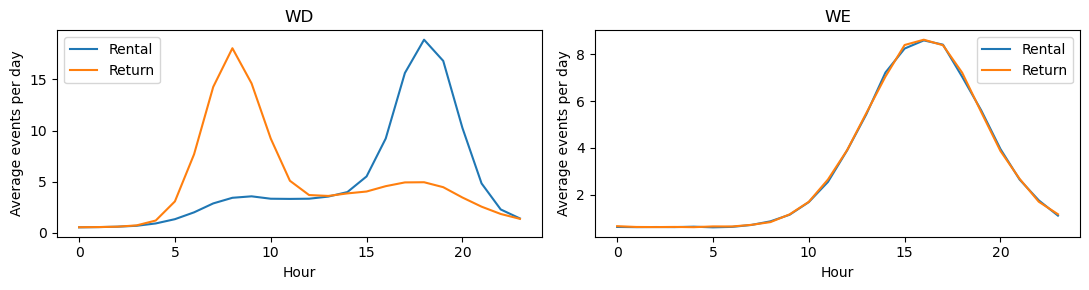

In [9]:
GROUP = 0  # TODO: 관심 있는 군집 번호
selected = bike[bike["cluster"] == GROUP]

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, n in zip(axes, ["wd", "we"], [261, 104]):
    for kind, label in [("r", "Rental"), ("b", "Return")]:
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), selected[cols].mean().to_numpy() / n, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Average events per day")
    ax.legend()
plt.tight_layout()
plt.show()

### 9. 계절적 특성도 살펴보기

`m01`~`m12`는 월별 **대여 총건수**입니다. 각 대여소의 연간 대여건수로 나누면 대여소 규모와 관계없이 계절적 패턴을 비교할 수 있습니다.

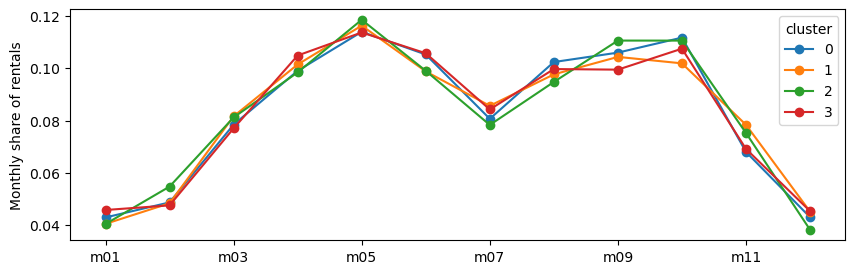

In [10]:
months = [f"m{m:02}" for m in range(1, 13)]
monthly_share = bike[months].div(bike["annual_rentals"], axis=0)
monthly_share.groupby(bike["cluster"]).mean().T.plot(marker="o", figsize=(10, 3))
plt.ylabel("Monthly share of rentals")
plt.show()

### 10. 분석 결과를 운영 방안으로 연결하기

| 군집 | 시간대별 대여·반납 특징 | 계절 특징 | 임시 유형 이름 | 운영상 제안과 그 근거 |
|---|---|---|---|---|
| 0 | | | | |
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

**✍️ 기록 ③ — 최종 판단**

1. 군집을 어떤 근거로 구분했나요? 실제로 유사한 패턴이 확인되나요?
2. 군집 한 곳을 선택해 **대여와 반납의 차이**가 나타나는 시간대를 설명하세요.
3. 대여소 운영 개선 아이디어를 하나 제안하세요. 다른 자료를 추가로 확인해야 한다면 무엇인가요?
4. AI가 제시한 해석 중 과장된 주장 하나를 찾아 수정하세요.

**주의:** 대여·반납의 차이만으로 실제 재고 부족이나 재배치 필요성을 확정할 수 없습니다. 대여소 위치, 운영일, 거치대 용량, 자전거 재배치 내역 등이 더 필요할 수 있습니다.

## 선택적 확장 · 2024년과 비교하기

2024년의 데이터를 같은 형식으로 준비할 수 있다면, **2025년의 군집 중심을 기준으로** 2024년 대여소의 유형을 분류해 보세요. 이렇게 하면 별도 K-means를 학습할 때 생기는 *군집 번호 불일치 문제*를 피할 수 있습니다. 아래 코드는 2024년 파일을 준비한 후에만 실행합니다.

```python
old = pd.read_csv("p5_station_profiles_2024.csv", dtype={"station_id": str}).set_index("station_id")
now = bike.set_index("station_id")
common = old.index.intersection(now.index)

old_r = old.loc[common, rent_cols].div(old.loc[common, "annual_rentals"], axis=0)
old_b = old.loc[common, return_cols].div(old.loc[common, "annual_returns"], axis=0)
old_groups = model.predict(pd.concat([old_r, old_b], axis=1))

pd.crosstab(old_groups, now.loc[common, "cluster"].to_numpy(), normalize="index").round(2)
```

*비교 해석:* 같은 대여소가 같은 유형으로 분류되었나요? 2025년에 만들어진 군집의 기준을 2024년에 적용했으므로, **연도별 독립적인 최적 군집**을 비교한 것은 아닙니다. 대여소의 운영 기간이나 데이터 수집 방식의 변화도 고려해야 합니다.

---

### 최종 제출

**실행한 노트북 + 분석 보고서 1~2쪽**

분석 질문 → 데이터 의미 → 군집 수 선택 → 대여·반납 패턴 → 운영 제안 → 한계 순서로 작성하세요. **코드의 길이가 아니라 판단 근거와 설명의 타당성**을 평가합니다.

- 원자료: [서울 열린데이터광장 — 대여이력 정보](https://data.seoul.go.kr/dataList/OA-15182/F/1/datasetView.do)
- 현재 동봉된 `p5_demo_station_profiles_2025.csv`는 **모의 데이터**입니다. 실제 서울시 관측 결과가 아닙니다.
- 실제 분석 파일은 교수자용 스크립트로 준비한 `p5_station_profiles_2025.csv`를 사용하세요.